# RCBNB-MB: 원자재별 레짐과 레짐별 인과 그래프

방법: Zan et al., *Beyond Stationarity in Time Series* (arXiv 2609.05150). 두 단계를 번갈아 반복한다.
1. 레짐별로 CBNB 인과 그래프를 추정한다 (PCMCI+ 로 뼈대·시차 방향, LiNGAM 으로 동시점 방향).
2. 각 주를 "그 주의 모든 변수를 Markov blanket 으로 가장 잘 예측하는 레짐"에 다시 배정한다.

- 데이터: `data/01_raw/causal_panel.parquet` (`uv run python analysis/causal_common.py` 로 다시 받는다) — 가격 로그 수익률 + drivers 전부, 2015-01-04 이후.
  가격과 일간 시장 변수는 주 마지막 값이다. 커피 답지가 설명하는 가격은 헤알 가격이다(예측 파이프라인의 USD 타깃과 다르다). 커피는 CEPEA 헤알 가격 이력이 DB 에 들어온 뒤에 넣는다 — 스냅샷에 가격이 없는 원자재는 자동으로 빠진다.
- 같은 주 방향 가정: 가격과 변수의 같은 주 링크는 `변수 → 가격` 으로 둔다(포지션·재고·ETF 보유량 `PFM.POS`·`FND.INV` 는 LiNGAM 에 맡긴다). 주간 자료에서 같은 주 방향은 데이터로 식별되지 않아서다.
- 고정: τ_max = 4, 유의수준 0.05.
- 레짐 수 r · 최소 레짐 크기 N_ℓ · 최대 전환 횟수 N_c 는 경제 지식으로 후보를 정하고 세 가지 방식(A 보류 표본 검정, B BIC, C 경제 지식 고정)으로 고른다.
- 채점: `docs/commodity_weekly_drivers.xlsx` 의 주별 원인표(2023-01 ~ 2026-10).

이미 본 기간을 탐색하는 분석이다. 예측 성능 평가가 아니다.

In [1]:
import hashlib, os, pickle, warnings

import lingam
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import sparse, stats
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.signal import find_peaks
from scipy.sparse.csgraph import connected_components
from tigramite import data_processing as pp
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.pcmci import PCMCI

from causal_common import (ALPHA, MISSING, SERIES, START, TAU, ROOT, attribution, load_key, make_panel, prices,
                           score_sets, score_weeks, sinks)  # 데이터·변환·답지·채점: analysis/causal_common.py

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"  # 병렬 작업 프로세스에도 적용
CACHE = ROOT / "data/07_reporting/rcbnb_mb"  # 적합 결과 캐시. 알고리즘 셀을 바꾸면 이 폴더를 지운다.
CACHE.mkdir(parents=True, exist_ok=True)

SEASON = 52          # 최소 레짐 크기 하한: 작황·계절 한 바퀴
R_MAX = 4            # 레짐 수 상한
BULL_BEAR = 0.20     # 강세·약세 전환 기준: 20% 등락
MIN_VALID = 52       # 레짐 안 유효 주가 이보다 적은 변수는 그 레짐 그래프에서 뺀다
HOLDOUT = 0.2        # 방식 A 에서 빼 두는 주의 비율
N_INIT, N_ITER = 20, 20  # 무작위 초기화 수, 초기화당 최대 반복
MILP_SECONDS = 10    # 배정 문제 한 번의 시간 제한

## 1. 변수 변환 — 계단형(월·분기) 변수의 정보 살리기

주간 차분을 하면 월·분기 변수는 80~95% 가 0 이 되고, τ = 4 로는 값이 바뀐 주 뒤 5주만 보게 된다.

| 변수 | 변환 |
| --- | --- |
| 주간 변수 | 1주 변화 (양수이고 금리·비율이 아니면 로그 차분) |
| 계단형, 발표값 열이 정상 (ADF p < 0.05) | 수준 그대로 |
| 계단형, 비정상 | 직전 발표값 대비 변화를 다음 발표까지 유지 |

발표 한 주기 전체가 lag 0 링크 하나에 모이고, 미래 값은 쓰지 않는다. 정보량의 상한은 발표 횟수다.
늦게 시작하는 변수는 빼지 않고 결측으로 둔다. 마지막에 모든 열을 z-score 로 맞춘다(식 (6) 이 변수별 제곱오차를 더한다).
변환 코드는 `analysis/causal_common.py` 의 `make_panel` — PCMCI-LPCMCI 노트북과 같은 함수를 쓴다.

In [2]:
panels = {s: make_panel(s) for s in SERIES}
sink = {s: sinks(*panels[s]) for s in SERIES}  # 같은 주 링크를 변수 → 가격 으로 가정하는 변수
for s, (X, info) in panels.items():
    print(f"\n== {s}: T={len(X)}, d={X.shape[1]}, 결측 비율={X.isna().mean().mean():.3f}")
    print(info.assign(변수=info.변수.str[:58]).to_string(index=False))


== coffee: T=619, d=20, 결측 비율=0.090
                                                        변수                   code                  변환 로그  변화 횟수  주간 변화 비율         시작
                                        Com_CBOE_VIX_Index     PFM.AST.VOLATILITY               주간 변화 로그    618      1.00 1990-01-07
Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE       PFM.POS.INVESTOR               주간 변화 로그    615      0.99 1986-01-19
Com_Cecafe_Brazil_Conillon_Coffee_Exports_Million_60kg_Bag         FND.TRD.EXPORT       계단형: 발표 변화 유지 로그    128      0.23 2016-01-31
Com_Conab_Brazil_Coffee_Arabica_Production_Estimate_Millio     FND.SUP.PRODUCTION       계단형: 발표 변화 유지 로그     37      0.06 2013-05-19
Com_Conab_Brazil_Coffee_Conilon_Production_Estimate_Millio     FND.SUP.PRODUCTION       계단형: 발표 변화 유지 로그     37      0.06 2013-05-19
Com_Conab_Brazil_Coffee_Total_Production_Estimate_Million_     FND.SUP.PRODUCTION       계단형: 발표 변화 유지 로그     37      0.06 2013-05-19
            Com_Cooxupe_Weekly_C

## 2. 알고리즘 (논문 Algorithm 1)

- `cbnb`: 레짐 안의 주만으로 window 그래프를 만든다. `A[i, j, τ]` 는 X^i(t−τ) → X^j(t).
- `markov_blankets`: 변수별 부모·자식·배우자를 (변수, 시차 −τ..+τ) 로.
- `sq_errors`: (레짐, 변수)마다 Markov blanket 선형 회귀 → 모든 주의 제곱오차.
- `assign`: 식 (7) 최소화. 제약은 주마다 레짐 하나, 레짐당 N_ℓ 주 이상, 레짐당 전환 N_c 이하.
- `run_init` / `fit`: 무작위 초기화 → 반복 → 손실이 가장 작은 초기화를 고른다.

In [3]:
def lagged(X):
    """Z[t, i, TAU + o] = X[t + o, i], o = -TAU..TAU (범위 밖은 NaN)."""
    T, d = X.shape
    Z = np.full((T, d, 2 * TAU + 1), np.nan)
    for o in range(-TAU, TAU + 1):
        lo, hi = max(0, -o), min(T, T - o)
        Z[lo:hi, :, TAU + o] = X[lo + o:hi + o]
    return Z


def ols_predict(P, y, fit, ok):
    """fit 행으로 적합하고 ok 행을 예측한다 (절편 포함)."""
    D = np.column_stack([np.ones(len(P)), P])
    return D[ok] @ np.linalg.lstsq(D[fit], y[fit], rcond=None)[0]


def cbnb(X, Z, sel, sink=None):
    T, d = X.shape
    act = np.flatnonzero((~np.isnan(X[sel])).sum(0) >= MIN_VALID)
    ix = np.ix_(act, act)
    frame = pp.DataFrame(np.nan_to_num(X[:, act], nan=MISSING), missing_flag=MISSING,
                         mask=np.repeat(~sel[:, None], len(act), 1))
    out = PCMCI(frame, ParCorr(significance="analytic", mask_type="y"), verbosity=0).run_pcmciplus(
        tau_min=0, tau_max=TAU, pc_alpha=ALPHA)
    A, val, S = np.zeros((d, d, TAU + 1), bool), np.full((d, d, TAU + 1), np.nan), np.zeros((d, d), bool)
    A[ix], val[ix], S[ix] = out["graph"] == "-->", out["val_matrix"], out["graph"][:, :, 0] != ""
    A[:, :, 0] = False  # 동시점 방향은 아래 noise-based 단계가 정한다
    n_comp, comp = connected_components(sparse.csr_matrix(S), directed=False)
    for c in range(n_comp):
        m = np.flatnonzero(comp == c)
        if len(m) < 2:
            continue
        par = sorted({(int(i), int(t)) for j in m for i, t in zip(*np.nonzero(A[:, j]))})  # 시차 부모를 공변량으로
        P = np.column_stack([Z[:, i, TAU - t] for i, t in par]) if par else np.empty((T, 0))
        ok = sel & ~np.isnan(P).any(1) & ~np.isnan(X[:, m]).any(1)
        E = np.column_stack([X[ok, j] - ols_predict(P, X[:, j], ok, ok) for j in m])
        rank = np.argsort(lingam.DirectLiNGAM().fit(E).causal_order_)  # rank[a] 가 작을수록 원인 쪽
        for a in range(len(m)):
            for b in range(len(m)):
                if S[m[a], m[b]] and rank[a] < rank[b]:
                    A[m[a], m[b], 0] = True
    if sink is not None:  # 같은 주 방향 가정: sink 변수와 가격(0번)의 같은 주 링크는 변수 → 가격
        fix = sink & S[:, 0]
        A[fix, 0, 0], A[0, fix, 0] = True, False
    return A, val


def markov_blankets(A):
    out = []
    for j in range(A.shape[0]):
        mb = {(int(i), -int(t)) for i, t in zip(*np.nonzero(A[:, j]))}
        for c, t in zip(*np.nonzero(A[j])):
            mb.add((int(c), int(t)))
            mb |= {(int(m), int(t - t2)) for m, t2 in zip(*np.nonzero(A[:, c]))}
        out.append(sorted(mb - {(j, 0)}))
    return out


def sq_errors(X, Z, mbs, train):
    r, (T, d) = len(mbs), X.shape
    E = np.full((r, T, d), np.nan)
    for k in range(r):
        for j in range(d):
            P = np.column_stack([Z[:, i, TAU + o] for i, o in mbs[k][j]]) if mbs[k][j] else np.empty((T, 0))
            ok = ~np.isnan(X[:, j]) & ~np.isnan(P).any(1)
            fit = ok & train[k]
            if fit.sum() > P.shape[1] + 1:
                E[k, ok, j] = (X[ok, j] - ols_predict(P, X[:, j], fit, ok)) ** 2
    E[:, np.isnan(E).any(0)] = 0  # 어느 레짐에서든 예측할 수 없는 항은 배정에 표를 던지지 않는다
    return E


def assign(cost, n_min, n_switch):
    r, T = cost.shape
    n, m = r * T, r * (T - 1)
    D = sparse.kron(sparse.eye(r), sparse.diags([-1.0, 1.0], [0, 1], shape=(T - 1, T)))
    rows = sparse.bmat([
        [sparse.kron(np.ones((1, r)), sparse.eye(T)), None],  # 주마다 레짐 하나
        [D, -sparse.eye(m)], [-D, -sparse.eye(m)],            # eta >= |gamma(t+1) - gamma(t)|
        [None, sparse.kron(sparse.eye(r), np.ones((1, T - 1)))],  # 레짐당 전환 <= N_c
        [sparse.kron(sparse.eye(r), np.ones((1, T))), None],      # 레짐당 주 수 >= N_l
    ], format="csr")
    lo = np.r_[np.ones(T), np.full(2 * m, -np.inf), np.zeros(r), np.full(r, n_min)]
    hi = np.r_[np.ones(T), np.zeros(2 * m), np.full(r, n_switch), np.full(r, T)]
    res = milp(np.r_[cost.ravel(), np.zeros(m)], constraints=LinearConstraint(rows, lo, hi),
               integrality=np.r_[np.ones(n), np.zeros(m)], bounds=Bounds(0, 1),
               options={"time_limit": MILP_SECONDS})
    if res.x is None:
        raise ValueError("배정 문제에 해가 없다")
    return res.x[:n].reshape(r, T).argmax(0)


def run_init(X, r, n_min, n_switch, seed, hold, sink=None):
    T, d = X.shape
    rng, Z = np.random.default_rng(seed), lagged(X)
    slack = T - r * n_min  # 무작위 연속 구간, 구간마다 n_min 주 이상
    sizes = np.diff(np.r_[0, np.sort(rng.integers(0, slack + 1, r - 1)), slack]) + n_min
    labels = np.repeat(rng.permutation(r), sizes)
    try:
        for it in range(N_ITER):
            train = [(labels == k) & ~hold for k in range(r)]
            graphs = [cbnb(X, Z, sel, sink) for sel in train]
            mbs = [markov_blankets(A) for A, _ in graphs]
            E = sq_errors(X, Z, mbs, train)
            cost = E.sum(-1)
            new = assign(np.where(hold, 0, cost), n_min, n_switch) if r > 1 else labels
            done, labels = bool((new == labels).all()), new
            if done:
                break
    except Exception as err:  # 표본 부족·특이 행렬 등: 이 초기화는 버린다
        return None
    order = pd.unique(labels)  # 레짐 번호 = 처음 등장한 순서
    week_loss = cost[labels, np.arange(T)]
    return dict(labels=np.argsort(order)[labels], graphs=[graphs[k] for k in order], mbs=[mbs[k] for k in order],
                week_loss=week_loss, loss=float(week_loss[~hold].sum()), converged=done, iters=it + 1,
                n_terms=int((E[0][~hold] > 0).sum()), n_coef=sum(len(b) + 1 for mb in mbs for b in mb))


def fit(X, r, n_min, n_switch, hold=None, sink=None):
    hold = np.zeros(len(X), bool) if hold is None else hold
    key = hashlib.md5(X.tobytes() + hold.tobytes() + (b"" if sink is None else sink.tobytes()) + repr((r, n_min, n_switch, TAU, ALPHA, N_INIT, N_ITER)).encode())
    path = CACHE / f"{key.hexdigest()}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    runs = Parallel(n_jobs=-1)(delayed(run_init)(X, r, n_min, n_switch, s, hold, sink) for s in range(N_INIT if r > 1 else 1))
    runs = [x for x in runs if x is not None]
    best = min(runs, key=lambda x: x["loss"]) if runs else None
    if best:
        best["n_ok"] = len(runs)
    path.write_bytes(pickle.dumps(best))
    return best

### 자체 점검 — 논문 5.1 의 합성 데이터

변수 6개, 길이 600, 앞 절반과 뒤 절반의 그래프가 다른 선형 모형. 레짐을 잘못 배정한 주의 비율(MER)이 10% 미만이어야 한다.

In [4]:
def simulate(seed, d=6, T=600, r=2):
    rng = np.random.default_rng(seed)
    while True:
        Bs = []
        for _ in range(r):
            B, order = np.zeros((2, d, d)), rng.permutation(d)  # B[tau, i, j]: X^i(t-tau) -> X^j(t)
            coef = lambda: rng.uniform(0.5, 0.9) * rng.choice([-1, 1])
            for i in range(d):
                B[1, i, i] = coef()
                for j in range(d):
                    if i != j and rng.random() < 0.3:
                        lag = int(rng.integers(0, 2))
                        if lag == 1 or order[i] < order[j]:
                            B[lag, i, j] = coef()
            Bs.append((B, np.argsort(order)))
        X, truth = np.zeros((T, d)), np.repeat(np.arange(r), T // r)
        for t in range(T):
            B, topo = Bs[truth[t]]
            fresh = t == 0 or truth[t] != truth[t - 1]  # 레짐의 첫 시점은 잡음에서 시작
            for j in topo:
                X[t, j] = rng.uniform(-0.1, 0.1) + (0 if fresh else X[t - 1] @ B[1, :, j]) + X[t] @ B[0, :, j]
        if np.abs(X).max() < 100:
            return X, truth


def demo():
    X, truth = simulate(seed=0)
    f = fit((X - X.mean(0)) / X.std(0), r=2, n_min=(2 * TAU + 1) * X.shape[1], n_switch=3)
    mer = min(np.mean(f["labels"] != truth), np.mean(f["labels"] == truth))
    print(f"합성 데이터 MER = {mer:.3f}, 레짐 크기 = {np.bincount(f['labels'])}, 성공한 초기화 = {f['n_ok']}/{N_INIT}")
    assert mer < 0.1


demo()

합성 데이터 MER = 0.005, 레짐 크기 = [301 299], 성공한 초기화 = 20/20


## 3. 후보 — 경제 지식으로 범위를 정한다

- **최소 레짐 크기** N_ℓ = max((2τ+1)·d, 52주). 앞은 논문의 식별 조건(Markov blanket 회귀가 풀리려면 필요한 주 수), 뒤는 작황·계절 한 바퀴.
- **레짐 수** r = 1 … min(4, ⌊T / N_ℓ⌋). r = 1 은 레짐이 없는 CBNB(기준선).
- **최대 전환 횟수** N_c ≤ P. P 는 구간 안에서 가격이 20% 이상 오르내린 강세·약세 전환점의 수.
  인과 구조가 가격 순환보다 자주 바뀐다고 볼 근거가 없다. 후보는 1, 2, 4, …, P.

In [5]:
def turning_points(series):
    logp = np.log(prices[prices.series == series].set_index("week").value[START:])
    prom = np.log(1 + BULL_BEAR)
    return logp, find_peaks(logp.values, prominence=prom)[0], find_peaks(-logp.values, prominence=prom)[0]


plans = {}
for s, (X, _) in panels.items():
    T, d = X.shape
    _, peaks, troughs = turning_points(s)
    n_min, P = max((2 * TAU + 1) * d, SEASON), max(len(peaks) + len(troughs), 1)
    r_max = min(R_MAX, T // n_min)
    grid = sorted({min(2 ** i, P) for i in range(P.bit_length() + 1)})
    cands = [(1, 0)] + [(r, c) for r in range(2, r_max + 1) for c in grid if r == 2 or c >= 2]  # 가운데 레짐은 전환이 2번
    plans[s] = dict(n_min=n_min, P=P, cands=cands)
    print(f"{s}: d={d}, T={T}, N_l={n_min}, r_max={r_max}, 전환점 P={P}, 후보 (r, N_c)={cands}")

coffee: d=20, T=619, N_l=180, r_max=3, 전환점 P=10, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4), (2, 8), (2, 10), (3, 2), (3, 4), (3, 8), (3, 10)]
copper: d=32, T=619, N_l=288, r_max=2, 전환점 P=5, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4), (2, 5)]
gold: d=25, T=619, N_l=225, r_max=2, 전환점 P=4, 후보 (r, N_c)=[(1, 0), (2, 1), (2, 2), (2, 4)]


## 4. 적합 — 후보마다 전체 표본 1번 + 보류 표본 1번

처음 돌리면 10코어에서 약 2시간 10분 걸린다(구리·금은 PCMCI+ 한 번에 수 초). 결과는 `data/07_reporting/rcbnb_mb/` 에 캐시되어 다시 돌리면 바로 끝난다.

In [6]:
fits = {}
for s, (X, _) in panels.items():
    hold = np.random.default_rng(0).random(len(X)) < HOLDOUT
    for r, c in plans[s]["cands"]:
        full, held = (fit(X.values, r, plans[s]["n_min"], c, h, sink[s]) for h in (None, hold))
        if full is None or held is None:
            print(f"{s} r={r} N_c={c}: 해 없음 — 후보에서 뺀다")
            continue
        fits[s, r, c] = dict(full=full, held=held, hold=hold)
        sw = int((np.diff(full["labels"]) != 0).sum())
        assert np.bincount(full["labels"]).min() >= plans[s]["n_min"] or r == 1
        assert all((np.diff(full["labels"] == k) != 0).sum() <= max(c, 0) for k in range(r))
        print(f"{s} r={r} N_c={c}: 손실={full['loss']:.1f} 크기={np.bincount(full['labels'])} 전환(전체)={sw} "
              f"수렴={full['converged']} 반복={full['iters']} 성공 초기화={full['n_ok']} | 보류 손실={held['week_loss'][hold].sum():.1f}")

coffee r=1 N_c=0: 손실=3726.0 크기=[619] 전환(전체)=0 수렴=True 반복=1 성공 초기화=1 | 보류 손실=772.5
coffee r=2 N_c=1: 손실=3147.8 크기=[219 400] 전환(전체)=1 수렴=True 반복=1 성공 초기화=20 | 보류 손실=661.2
coffee r=2 N_c=2: 손실=3147.8 크기=[402 217] 전환(전체)=2 수렴=True 반복=2 성공 초기화=20 | 보류 손실=649.6
coffee r=2 N_c=4: 손실=3138.1 크기=[283 336] 전환(전체)=3 수렴=True 반복=3 성공 초기화=20 | 보류 손실=657.3
coffee r=2 N_c=8: 손실=2937.6 크기=[325 294] 전환(전체)=8 수렴=True 반복=6 성공 초기화=20 | 보류 손실=642.1
coffee r=2 N_c=10: 손실=2914.6 크기=[304 315] 전환(전체)=10 수렴=True 반복=9 성공 초기화=20 | 보류 손실=703.7
coffee r=3 N_c=2: 손실=2574.9 크기=[190 234 195] 전환(전체)=3 수렴=True 반복=2 성공 초기화=20 | 보류 손실=728.4
coffee r=3 N_c=4: 손실=2561.1 크기=[201 181 237] 전환(전체)=6 수렴=True 반복=3 성공 초기화=20 | 보류 손실=609.6
coffee r=3 N_c=8: 손실=3017.7 크기=[256 181 182] 전환(전체)=12 수렴=True 반복=8 성공 초기화=20 | 보류 손실=663.6
coffee r=3 N_c=10: 손실=2352.2 크기=[241 194 184] 전환(전체)=15 수렴=True 반복=6 성공 초기화=20 | 보류 손실=642.4
copper r=1 N_c=0: 손실=3292.8 크기=[619] 전환(전체)=0 수렴=True 반복=1 성공 초기화=1 | 보류 손실=1101.0
copper r=2 N_c=1: 손실=2712.9 크기=

## 5. 선택 — 세 가지 방식

| 방식 | 규칙 |
| --- | --- |
| A 보류 표본 검정 | 20% 의 주를 빼고 적합한다(뺀 주는 배정에서 비용 0 이라 이웃 레짐을 따른다). r = 1 에서 시작해 후보를 단순한 순서로 보면서, 뺀 주의 손실이 Wilcoxon 부호순위 단측 검정 p < 0.05 로 줄 때만 옮긴다. |
| B BIC | log(L/n) + (회귀 계수 수 + 전환 수)·log(n)/n 이 가장 작은 후보 (n = 채점된 항의 수). |
| C 경제 지식 고정 | r = 2 (수급이 끄는 시기 / 거시·금융이 끄는 시기), N_c = P. |

In [7]:
def bic(f):
    n = f["n_terms"]  # 후보마다 채점되는 항의 수가 조금 달라 항 하나당 값으로 비교한다
    return np.log(f["loss"] / n) + (f["n_coef"] + (np.diff(f["labels"]) != 0).sum()) * np.log(n) / n


chosen, rows = {}, []
for s in SERIES:
    mine = {k[1:]: v for k, v in fits.items() if k[0] == s}
    cur = (1, 0)
    for cand in sorted(mine):
        if cand == (1, 0):
            continue
        h = mine[cand]["hold"]
        p = stats.wilcoxon(mine[cand]["held"]["week_loss"][h], mine[cur]["held"]["week_loss"][h], alternative="less").pvalue
        rows.append((s, cand, cur, mine[cand]["held"]["week_loss"][h].sum(), mine[cur]["held"]["week_loss"][h].sum(), p, bic(mine[cand]["full"])))
        if p < ALPHA:
            cur = cand
    fixed = (2, plans[s]["P"])
    chosen[s] = {"r=1 기준선": (1, 0), "A 보류 표본 검정": cur, "B BIC": min(mine, key=lambda k: bic(mine[k]["full"])),
                 "C 경제 지식 고정": fixed if fixed in mine else (1, 0)}
    print(s, "r=1 BIC =", round(bic(mine[1, 0]["full"]), 4), "→", chosen[s])
pd.DataFrame(rows, columns=["원자재", "후보 (r, N_c)", "비교 대상", "보류 손실", "비교 대상 보류 손실", "p", "BIC"]).round(4)

coffee r=1 BIC = -0.735 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (2, 2), 'B BIC': (1, 0), 'C 경제 지식 고정': (2, 10)}
copper r=1 BIC = -0.6831 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (2, 1), 'B BIC': (1, 0), 'C 경제 지식 고정': (2, 5)}
gold r=1 BIC = -0.88 → {'r=1 기준선': (1, 0), 'A 보류 표본 검정': (1, 0), 'B BIC': (1, 0), 'C 경제 지식 고정': (2, 4)}


,원자재,"후보 (r, N_c)",비교 대상,보류 손실,비교 대상 보류 손실,p,BIC
0,coffee,"(2, 1)","(1, 0)",661.1597,772.5405,0.0001,-0.5972
1,coffee,"(2, 2)","(2, 1)",649.6169,661.1597,0.0495,-0.5961
2,coffee,"(2, 4)","(2, 2)",657.3283,649.6169,0.9229,-0.5354
3,coffee,"(2, 8)","(2, 2)",642.0755,649.6169,0.2309,-0.5703
4,coffee,"(2, 10)","(2, 2)",703.6509,649.6169,0.9858,-0.5999
5,coffee,"(3, 2)","(2, 2)",728.4051,649.6169,0.9991,-0.2301
6,coffee,"(3, 4)","(2, 2)",609.5903,649.6169,0.0615,-0.4196
7,coffee,"(3, 8)","(2, 2)",663.6454,649.6169,0.7731,-0.4905
8,coffee,"(3, 10)","(2, 2)",642.3993,649.6169,0.0956,-0.5993
9,copper,"(2, 1)","(1, 0)",1084.2427,1100.9695,0.0090,-0.2941


## 6. 답지 채점 — `commodity_weekly_drivers.xlsx` (2023-01 ~ 2026-10)

답지는 "이번 주 가격이 왜 움직였는가"를 주마다 적은 표다. 두 층으로 나눠 본다(함수는 `causal_common.py`, PCMCI-LPCMCI 노트북과 같다).

**(가) 변수 집합.** 그 주 레짐의 그래프에서 고른 변수 집합이 그 주의 답지 인용 변수를 하나 이상 포함하는 주의 비율(포함률)과,
같은 크기의 무작위 집합의 기대 포함률(우연). 시차·방향·그 주의 움직임은 보지 않는다.
- 부모: 가격의 부모(같은 주는 가정 포함). 인접: 부모 + 자식. MB: 인접 + 배우자(Markov blanket) — 이전 판의 "원인 적중률"이 이 MB 포함률이다.

**(나) 주별 귀속.** 레짐마다 가격을 그 레짐 그래프의 부모 항에 회귀하고(그 레짐의 주로 적합), 주 w 의 기여 Σ_τ β·x(w − τ) 가 큰 순서로 변수를 세운다.
- top-k 적중률 = 상위 k 개에 답지 인용 변수가 있는 주의 비율, 우연 = 무작위 k 개의 기대 적중률. `(전체 주)` 는 분모가 답지 기간의 모든 주.
- 방향 일치 = top-3 적중 주에서 인용 변수 기여 합의 부호가 답지 등락률의 부호와 같은 비율.

**Cramér's V**: 레짐과 답지 `요인 유형` 의 연관. p 는 요인 유형 열을 순환 이동한 순열 검정(주간 자기상관 때문에 카이제곱 p 를 쓰지 않는다).
답지 기간에 레짐이 하나뿐이면 판정할 수 없다.

In [8]:
def cramers_v(a, b):
    tab = pd.crosstab(a, b).values
    if min(tab.shape) < 2:
        return np.nan
    return np.sqrt(stats.chi2_contingency(tab, correction=False)[0] / (tab.sum() * (min(tab.shape) - 1)))


def score(f, X, key):
    cols = list(X.columns)
    lab = pd.Series(f["labels"], index=X.index)
    parents, sets = [], {"부모": [], "인접": [], "MB": []}
    for (A, _), mb in zip(f["graphs"], f["mbs"]):  # 가격 = 0번 열
        par = {(cols[i], -o) for i, o in mb[0] if o <= 0 and A[i, 0, -o]}  # 부모 항 (가격 자기 시차 포함)
        near = {c for c, _ in par} | {cols[i] for i, o in mb[0] if o >= 0 and A[0, i, o]}
        parents.append(par)
        for name, S in zip(sets, ({c for c, _ in par}, near, {cols[i] for i, _ in mb[0]})):
            sets[name].append(S - {"price"})
    out = {}
    for name, by_regime in sets.items():
        sc = score_sets(lab.map(lambda k: by_regime[k]), X, key)
        out |= {f"{name} 크기": sc["집합 크기"], f"{name} 포함률": sc["포함률"], f"{name} 우연": sc["우연"]}
    contrib = pd.concat([attribution(X, parents[k], lab == k)[lab == k] for k in range(len(parents))]).sort_index()
    week = score_weeks(contrib, X, key)
    in_key = lab.reindex(key.index).dropna().astype(int)
    types = key.type.loc[in_key.index].values
    v = cramers_v(in_key.values, types)
    shifts = [cramers_v(in_key.values, np.roll(types, i)) for i in range(1, len(in_key))]
    return out, {"답지 기간 레짐 수": in_key.nunique(), **week,
                 "Cramér V": v, "V 의 p": np.nan if np.isnan(v) else (1 + sum(x >= v for x in shifts)) / len(in_key)}, contrib


keys = {s: load_key(s) for s in SERIES}
set_rows, week_rows, contribs = [], [], {}  # contribs: 리더보드 내보내기(마지막 절)가 쓴다
for s in SERIES:
    for m, (r, c) in chosen[s].items():
        head = {"원자재": s, "방식": m, "r": r, "N_c": c}
        a, b, contribs[s, m] = score(fits[s, r, c]["full"], panels[s][0], keys[s])
        set_rows.append({**head, "손실": fits[s, r, c]["full"]["loss"], **a})
        week_rows.append({**head, **b})
    X = panels[s][0]
    week_rows.append({"원자재": s, "방식": "기준: |z| 크기 (그래프 없음)", **score_weeks(X.drop(columns="price").fillna(0), X, keys[s]),
                      "방향 일치 (top3 적중 주)": np.nan})  # z 의 부호는 가격 방향이 아니다
summary, week_summary = pd.DataFrame(set_rows), pd.DataFrame(week_rows)
summary.round(3)

,원자재,방식,r,N_c,손실,부모 크기,부모 포함률,부모 우연,인접 크기,인접 포함률,인접 우연,MB 크기,MB 포함률,MB 우연
0,coffee,r=1 기준선,1,0,3725.967,2.000,0.179,0.105,4.000,0.210,0.211,4.000,0.210,0.211
1,coffee,A 보류 표본 검정,2,2,3147.822,3.000,0.198,0.158,4.000,0.210,0.211,4.000,0.210,0.211
2,coffee,B BIC,1,0,3725.967,2.000,0.179,0.105,4.000,0.210,0.211,4.000,0.210,0.211
3,coffee,C 경제 지식 고정,2,10,2914.603,2.049,0.062,0.108,3.000,0.074,0.158,4.901,0.093,0.258
4,copper,r=1 기준선,1,0,3292.845,5.000,0.269,0.161,7.000,0.280,0.226,13.000,0.360,0.419
5,copper,A 보류 표본 검정,2,1,2712.922,3.000,0.223,0.097,5.000,0.234,0.161,9.000,0.331,0.290
6,copper,B BIC,1,0,3292.845,5.000,0.269,0.161,7.000,0.280,0.226,13.000,0.360,0.419
7,copper,C 경제 지식 고정,2,5,2829.490,3.000,0.223,0.097,5.000,0.234,0.161,8.000,0.274,0.258
8,gold,r=1 기준선,1,0,4087.016,3.000,0.196,0.125,4.000,0.206,0.167,8.000,0.320,0.333
9,gold,A 보류 표본 검정,1,0,4087.016,3.000,0.196,0.125,4.000,0.206,0.167,8.000,0.320,0.333


In [9]:
week_summary.round(3)

,원자재,방식,r,N_c,답지 기간 레짐 수,답지 주 수,전체 주 수,입력 밖 인용,top1,top1 우연,top1 (전체 주),top3,top3 우연,top3 (전체 주),방향 일치 (top3 적중 주),Cramér V,V 의 p
0,coffee,r=1 기준선,1.0,0.0,1.0,162,200,0,0.136,0.053,0.110,0.173,0.158,0.140,0.786,NaN,NaN
1,coffee,A 보류 표본 검정,2.0,2.0,1.0,162,200,0,0.093,0.053,0.075,0.191,0.158,0.155,0.774,NaN,NaN
2,coffee,B BIC,1.0,0.0,1.0,162,200,0,0.136,0.053,0.110,0.173,0.158,0.140,0.786,NaN,NaN
3,coffee,C 경제 지식 고정,2.0,10.0,2.0,162,200,0,0.031,0.053,0.025,0.056,0.158,0.045,0.556,0.142,0.605
4,coffee,기준: |z| 크기 (그래프 없음),NaN,NaN,NaN,162,200,0,0.154,0.053,0.125,0.253,0.158,0.205,NaN,NaN,NaN
5,copper,r=1 기준선,1.0,0.0,1.0,175,200,13,0.051,0.032,0.045,0.223,0.097,0.195,0.744,NaN,NaN
6,copper,A 보류 표본 검정,2.0,1.0,1.0,175,200,13,0.080,0.032,0.070,0.223,0.097,0.195,0.769,NaN,NaN
7,copper,B BIC,1.0,0.0,1.0,175,200,13,0.051,0.032,0.045,0.223,0.097,0.195,0.744,NaN,NaN
8,copper,C 경제 지식 고정,2.0,5.0,1.0,175,200,13,0.080,0.032,0.070,0.223,0.097,0.195,0.769,NaN,NaN
9,copper,기준: |z| 크기 (그래프 없음),NaN,NaN,NaN,175,200,13,0.069,0.032,0.060,0.206,0.097,0.180,NaN,NaN,NaN


## 7. 레짐 그림

위: 가격과 20% 전환점. 가운데: 방식별 레짐. 아래: 답지의 주별 요인 유형(유형마다 한 줄, 눈금 하나가 한 주).

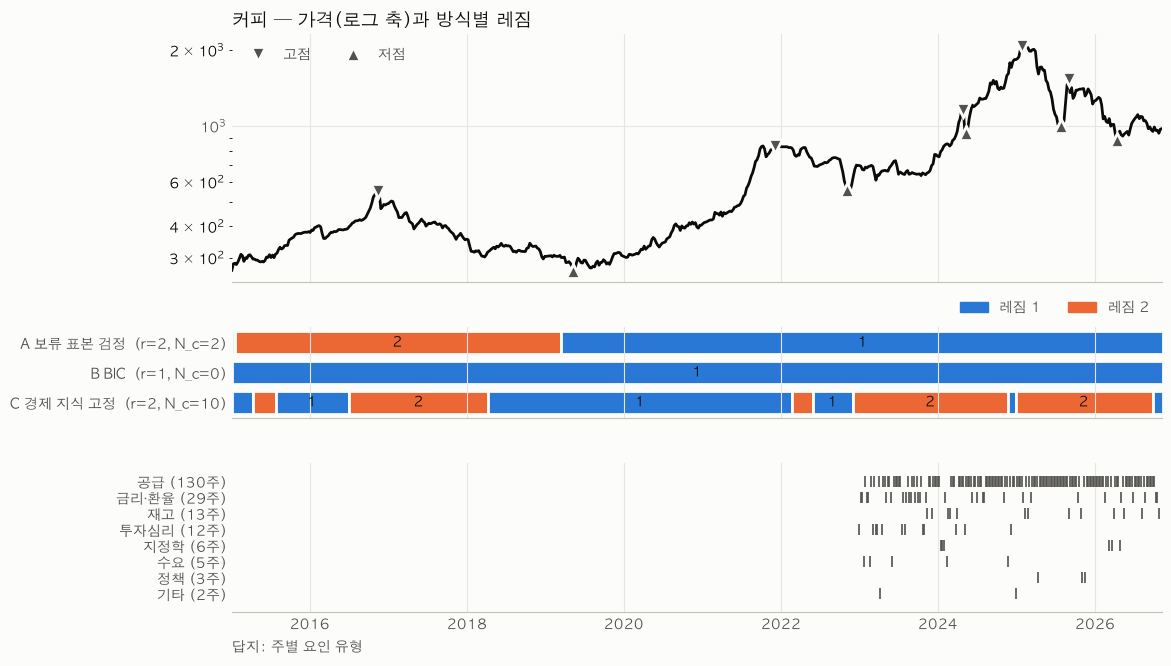

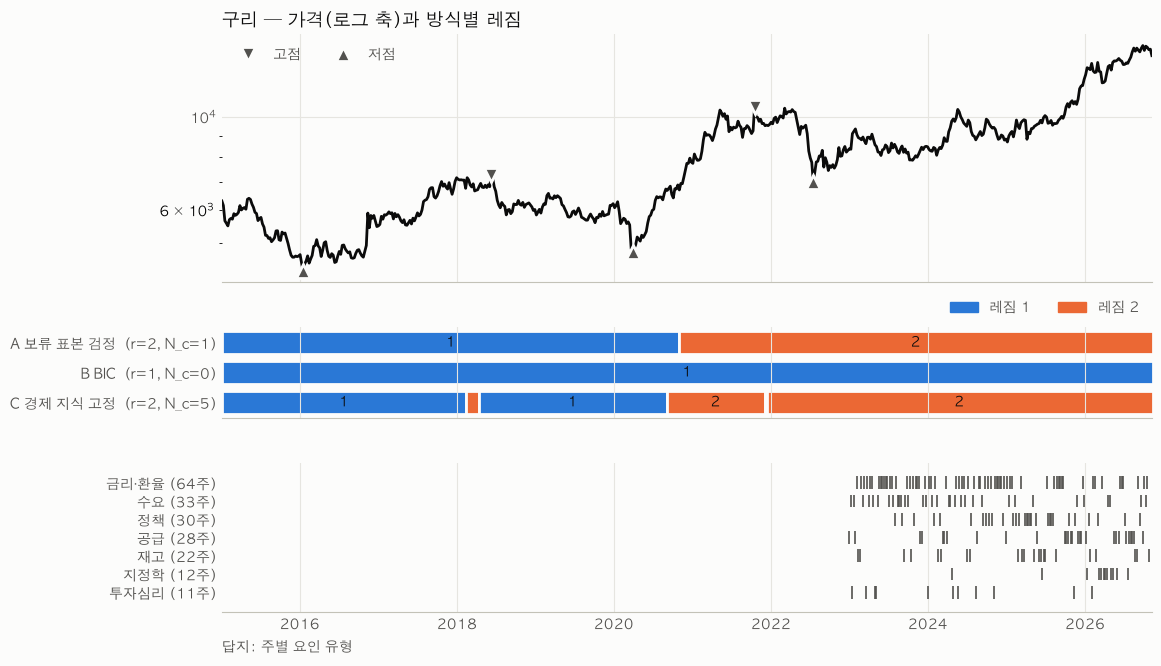

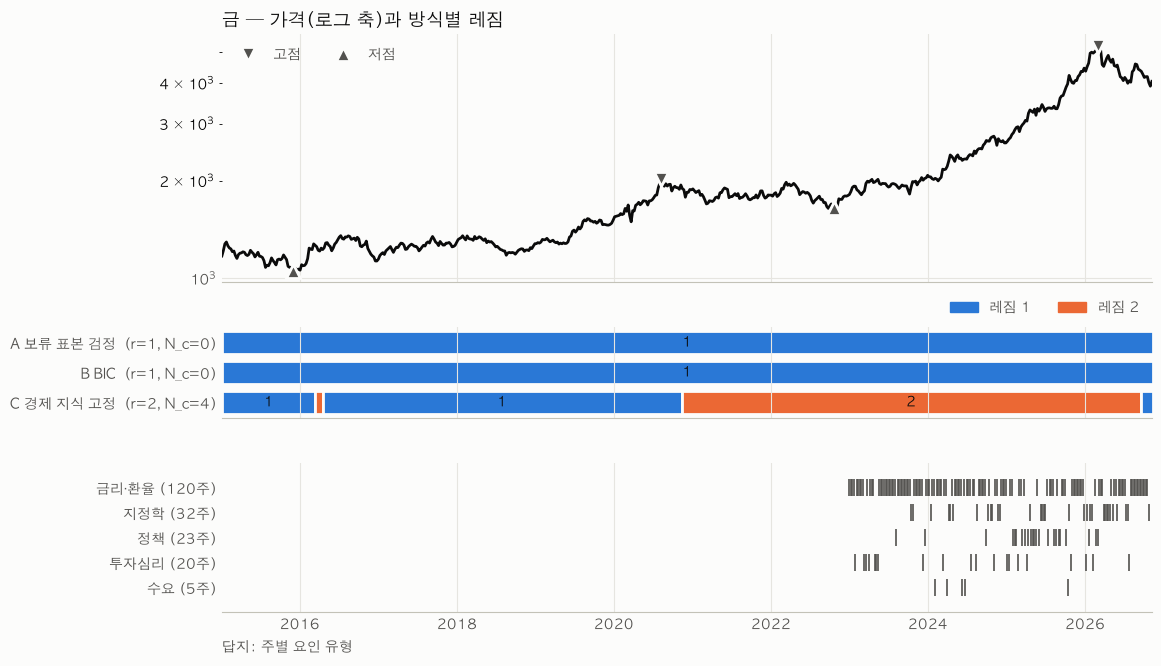

In [10]:
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}  # 한글 글꼴: 설치된 첫 번째 것
plt.rcParams.update({"font.family": next((f for f in ("AppleGothic", "Malgun Gothic", "NanumGothic") if f in have), "sans-serif"),
                     "axes.unicode_minus": False})
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
REGIME = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # 레짐 번호(처음 등장한 순서)에 고정


def plot_regimes(s):
    X, methods = panels[s][0], [m for m in chosen[s] if m != "r=1 기준선"]
    logp, peaks, troughs = turning_points(s)
    types = keys[s].type.value_counts().index[::-1]
    fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, facecolor=SURFACE,
                                     gridspec_kw={"height_ratios": [3, 1.1, 1.8], "hspace": 0.28})
    a0.plot(logp.index, np.exp(logp), color=INK, lw=2)
    a0.plot(logp.index[peaks], np.exp(logp.values[peaks]), "v", ms=10, color=MUTED, mec=SURFACE, mew=2, ls="", label="고점")
    a0.plot(logp.index[troughs], np.exp(logp.values[troughs]), "^", ms=10, color=MUTED, mec=SURFACE, mew=2, ls="", label="저점")
    a0.set_yscale("log")
    a0.set_title(f"{SERIES[s]} — 가격(로그 축)과 방식별 레짐", loc="left", color=INK, fontsize=13)
    a0.legend(frameon=False, loc="upper left", ncol=2, labelcolor=MUTED)
    week = pd.Timedelta(weeks=1)
    for y, m in enumerate(methods):
        r, c = chosen[s][m]
        lab = fits[s, r, c]["full"]["labels"]
        edges = np.r_[0, np.flatnonzero(np.diff(lab)) + 1, len(lab)]
        for lo, hi in zip(edges[:-1], edges[1:]):
            a1.broken_barh([(X.index[lo], (hi - lo) * week)], (y - 0.38, 0.76), color=REGIME[lab[lo]], ec=SURFACE, lw=2)
            if hi - lo >= 26:  # 색만으로 구분하지 않도록 레짐 번호를 적는다
                a1.text(X.index[(lo + hi) // 2], y, str(lab[lo] + 1), ha="center", va="center", color=INK, fontsize=10)
    a1.set_yticks(range(len(methods)), [f"{m}  (r={chosen[s][m][0]}, N_c={chosen[s][m][1]})" for m in methods])
    a1.invert_yaxis()
    n_reg = max(chosen[s][m][0] for m in methods)
    a1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=REGIME[k]) for k in range(n_reg)],
              labels=[f"레짐 {k + 1}" for k in range(n_reg)], frameon=False, ncol=n_reg, loc="lower right",
              bbox_to_anchor=(1, 0.98), labelcolor=MUTED)
    a2.eventplot([keys[s].index[keys[s].type == t] for t in types], colors=MUTED, linelengths=0.7, linewidths=1.2)
    a2.set_yticks(range(len(types)), [f"{t} ({(keys[s].type == t).sum()}주)" for t in types])
    a2.set_xlabel("답지: 주별 요인 유형", color=MUTED, loc="left")
    for ax in (a0, a1, a2):
        ax.set_facecolor(SURFACE)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED, length=0)
        ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    a0.grid(axis="y", color="#e6e5e0", lw=0.8)
    a0.set_xlim(X.index[0], X.index[-1])
    plt.show()


for s in SERIES:
    plot_regimes(s)

## 8. 레짐별 가격의 Markov blanket

방식 A·B·C 가 고른 후보마다(같은 후보는 한 번만), 레짐별로 가격과 직접 이어진 변수를 적는다.
시차는 가격 시점 기준(−2 = 2주 전 값, +1 = 1주 뒤 값). 강도는 PCMCI+ 의 편상관. `답지 인용` 은 그 레짐의 답지 주들에서 그 변수가 원인으로 인용된 횟수다.

In [11]:
def blanket_table(s, r, c):
    X, f = panels[s][0], fits[s, r, c]["full"]
    cols = list(X.columns)
    lab = pd.Series(f["labels"], index=X.index)
    rows = []
    for k, ((A, val), mb) in enumerate(zip(f["graphs"], f["mbs"])):
        weeks = lab.index[lab == k]
        cites = keys[s].cited.reindex(weeks).dropna().explode().value_counts()
        for i, o in mb[0]:
            if o <= 0 and A[i, 0, -o]:
                kind, strength = "부모 → 가격" + (" (가정)" if o == 0 and sink[s][i] else ""), val[i, 0, -o]
            elif o >= 0 and A[0, i, o]:
                kind, strength = "가격 → 자식", val[0, i, o]
            else:
                kind, strength = "배우자 (자식의 다른 부모)", np.nan
            rows.append((f"레짐 {k + 1}", f"{weeks[0].date()} ~ {weeks[-1].date()} 중 {len(weeks)}주", cols[i][:60], o, kind,
                         strength, int(cites.get(cols[i], 0))))
    return pd.DataFrame(rows, columns=["레짐", "기간", "변수", "시차(주)", "관계", "강도", "답지 인용"]).round(3)


for s in SERIES:
    for r, c in sorted(set(chosen[s].values())):
        print(f"\n===== {SERIES[s]}  r={r}, N_c={c}  ({', '.join(m for m, v in chosen[s].items() if v == (r, c))})")
        print(blanket_table(s, r, c).to_string(index=False))


===== 커피  r=1, N_c=0  (r=1 기준선, B BIC)
  레짐                             기간                                                           변수  시차(주)              관계     강도  답지 인용
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                                        price     -1         부모 → 가격  0.187      0
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                                        price      1         가격 → 자식  0.187      0
레짐 1 2015-01-04 ~ 2026-11-08 중 619주 Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F     -1 배우자 (자식의 다른 부모)    NaN      3
레짐 1 2015-01-04 ~ 2026-11-08 중 619주 Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      0         가격 → 자식  0.184      3
레짐 1 2015-01-04 ~ 2026-11-08 중 619주 Com_CFTC_Commitments_Of_Traders_Legacy_Report_COFFEE_C_ICE_F      1         가격 → 자식  0.276      3
레짐 1 2015-01-04 ~ 2026-11-08 중 619주                                       Com_Fed_H10_EX_BRL_USD      0    부모 → 가격 (가정)  0.114     26
레짐 1 2015-01-04 ~ 2026

## 9. 결과 요약과 한계

2026-11-08 까지의 스냅샷(`causal_panel.parquet`)과 2026-11-13 에 고친 답지로 돌린 결과다. 커피 가격은 CEPEA 헤알 가격이다.
데이터나 답지를 바꾸면 6절의 표를 다시 읽는다.

| 원자재 | A 보류 표본 검정 | B BIC | C 경제 지식 고정 | 주별 귀속 top-3 (r=1 → A / B / C), 우연 | top-1 (r=1 → A / B / C), 우연 |
| --- | --- | --- | --- | --- | --- |
| 커피 | r=2, N_c=2 | r=1 | r=2, N_c=10 | 0.17 → 0.19 / 0.17 / 0.06, 우연 0.16 | 0.14 → 0.09 / 0.14 / 0.03, 우연 0.05 |
| 구리 | r=2, N_c=1 | r=1 | r=2, N_c=5 | 0.22 → 0.22 / 0.22 / 0.22, 우연 0.10 | 0.05 → 0.08 / 0.05 / 0.08, 우연 0.03 |
| 금 | r=1 | r=1 | r=2, N_c=4 | 0.20 → 0.20 / 0.20 / 0.17, 우연 0.13 | 0.12 → 0.12 / 0.12 / 0.12, 우연 0.04 |

- **레짐을 나눠도 답지 재현은 나아지지 않는다.** top-3 적중률은 레짐 없는 그래프(r=1)와 같거나 낮다. 커피의 C(레짐 2개, 전환 10번)는 0.06 으로 우연(0.16)보다 낮다.
  커피 A 는 top-3 가 0.02 오르지만 top-1 은 0.14 에서 0.09 로 내린다.
- **데이터로 고른 레짐(A)은 답지 기간(2023 ~)을 나누지 않는다.** 커피·구리의 A 는 레짐 2개를 골랐지만 답지 기간은 전부 한 레짐이다.
  답지 기간에 레짐이 둘인 것은 C(커피·금)뿐이고, 레짐과 답지 `요인 유형` 의 연관은 유의하지 않다(Cramér V 0.14, p = 0.61 / 0.10, p = 0.92).
- **부모 집합은 우연보다 높고, MB 집합은 우연과 같다.** r=1 의 부모 포함률 / 우연: 커피 0.18 / 0.11, 구리 0.27 / 0.16, 금 0.20 / 0.13.
  MB 는 커피 0.21 / 0.21, 구리 0.36 / 0.42, 금 0.32 / 0.33 이다. 이전 판의 "원인 적중률"은 이 MB 포함률이었고 우연 기준선이 없었다.
- 그래프 없이 그 주의 |z| 가 큰 순서로 세운 기준(top-3: 커피 0.25, 구리 0.21, 금 0.21)이 어느 레짐 설정과도 비슷하거나 높다.
  남은 격차는 레짐이나 그래프 탐색이 아니라 답지(그 주 뉴스가 든 이유)와 주간 자료의 관계에서 온다 — `PCMCI-LPCMCI.ipynb` 5절과 같은 결론이다.
- 맞힌 주의 방향 일치율은 r=1 기준 커피 0.79, 구리 0.74, 금 0.92 다.

한계
- 같은 주 링크의 방향 `변수 → 가격` 은 가정이다(포지션·재고·ETF 보유량 제외). 8절 표에 `(가정)` 으로 적었다. 가정으로 뒤집은 간선이 LiNGAM 순서와 어긋나 같은 주 순환이 생길 수 있다(손실 계산에는 지장이 없다).
- drivers 전부 + τ = 4 이면 N_ℓ = 9d 가 커서(커피 180, 구리 288, 금 225주 / 전체 619주) 구리·금은 레짐이 2개까지고, 두 레짐이 표본을 거의 반씩 나눠 가져야 한다.
- 손실이 N_c 에 대해 단조가 아니다(구리 N_c = 2, 4, 5 가 N_c = 1 보다 손실이 크고, 커피 r=3 은 N_c = 8 이 N_c = 4 보다 크다). 초기화 20개로는 가장 좋은 해를 못 찾는 경우가 있다.
  구리 r=2, N_c=1(방식 A 가 고른 후보)은 20번 반복 안에 수렴하지 않았다.
- 양 끝 4주는 시차 때문에 비용이 0 이라 배정이 임의다(그림 끝의 얇은 조각).
- 계단형 변수끼리의 검정은 유효 표본이 발표 횟수라 p 값이 낙관적이다.
- 방식 A 의 순차 검정은 다중 비교를 보정하지 않는다.
- 귀속 회귀는 결측을 0(평균)으로 두고 레짐의 주 전체에 한 번 적합한다. 계수는 이미 본 기간에서 나온 것이다.
- 답지는 2023 이후만 있어 그 전 레짐은 채점되지 않는다. 답지가 인용한 변수 중 DB 주간 뷰에 없는 것(구리 13건, 금 1건)은 입력에 없다.


## 리더보드 내보내기

위 표와 같은 귀속·채점을 `analysis/notebook_board.py` 형식으로 쓴다. 올리기: `uv run python tools/log_causal_leaderboard.py --path <출력 폴더>`. 이 노트북의 평가 조건(`protocol`)은 `in_sample_full` 라 다른 조건의 run 과 같은 순위에 넣지 않는다.


In [12]:
from notebook_board import export

rows = []
for s in SERIES:
    X = panels[s][0]
    for m in chosen[s]:
        rows.append(dict(name=m, phase="all", series=s, contrib=contribs[s, m], X=X, key=keys[s], axis="regime",
                         parent="" if m == "r=1 기준선" else "r=1 기준선"))
    rows.append(dict(name="기준: |z| 크기 (그래프 없음)", phase="all", series=s, contrib=X.drop(columns="price").fillna(0), X=X, key=keys[s],
                     axis="baseline", override={"방향 일치 (top3 적중 주)": np.nan}))
export("rcbnb_mb", "RCBNB-MB.ipynb", rows, "in_sample_full",
       specs={m: dict(r_N_c={s: list(chosen[s][m]) for s in SERIES}) for m in chosen[next(iter(SERIES))]})


exported 15 rows, 3 comparisons → /Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/rcbnb_mb/87035dec35203c6c72d6


PosixPath('/Users/sonet/Desktop/01_riotinto/data/07_reporting/causal_notebooks/rcbnb_mb/87035dec35203c6c72d6')